# 02_treino.ipynb — Treino, Avaliação e Exportação do Modelo

**Projeto**: Predição de Readmissão Hospitalar 30 Dias (`readmission_30d`)
**Modelo**: Naive Bayes (Pipeline: `ColumnTransformer` + `GaussianNB`)
**Autor**: Patric — Disciplina Probabilidade e Estatística (IFCE)

---

## Objetivos deste Notebook

1. **Reproduzir a base final** (mesmo feature engineering do `01_exploracao.ipynb`)
2. **Split estratificado** 80/20 com `random_state=42`
3. **Pipeline completo**: `ColumnTransformer` (StandardScaler + OneHotEncoder) → `GaussianNB`
4. **Treino** no conjunto de treino apenas (sem vazamento)
5. **Avaliação completa**: Accuracy, Precision/Recall/F1 (macro), Matriz de Confusão, AUC-ROC, AUC-PR, Classification Report
6. **Análise de erros** (FP/FN) e interpretação clínica
7. **Exportação** do pipeline completo para `../backend/model/modelo_nb.joblib`
8. **Criar script de teste standalone** (`ml/teste_carregamento.py`)
9. **Atualizar `ml/CONTRATO.md`** com features finais e ordem exata

## 1. Imports e Configuração

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path
import joblib
import json

# ML imports
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from scipy.stats import pointbiserialr

# Configurações
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

RANDOM_STATE = 42
TEST_SIZE = 0.2

DATA_DIR = Path('../data')
MODEL_DIR = Path('../backend/model')
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(f'Model directory: {MODEL_DIR.absolute()}')

Model directory: W:\projetos\hospital-management\ml\notebooks\..\backend\model


## 2. Reproduzir Feature Engineering (idêntico ao notebook 01)

> **Importante**: Copiar exatamente o mesmo código do `01_exploracao.ipynb` para garantir features idênticas.

In [2]:
# --- CARREGAMENTO ---
patients = pd.read_csv(DATA_DIR / 'patients.csv')
visits = pd.read_csv(DATA_DIR / 'visits_encounters.csv')
clinical = pd.read_csv(DATA_DIR / 'clinical_details.csv')
pharmacy = pd.read_csv(DATA_DIR / 'pharmacy_prescriptions.csv')

print('Shapes:', patients.shape, visits.shape, clinical.shape, pharmacy.shape)

Shapes: (5000, 21) (13214, 18) (13214, 22) (26715, 16)


In [3]:
# --- PHARMACY AGG ---
# Flags derivadas de therapeutic_class (não existem direto no CSV)
pharmacy_flags = pharmacy.copy()
pharmacy_flags['is_anticoagulant'] = (pharmacy_flags['therapeutic_class'] == 'Anticoagulant').astype(int)
pharmacy_flags['is_beta_blocker'] = (pharmacy_flags['therapeutic_class'] == 'Beta-Blocker').astype(int)
pharmacy_flags['is_diuretic'] = (pharmacy_flags['therapeutic_class'] == 'Loop Diuretic').astype(int)
pharmacy_flags['is_insulin'] = (pharmacy_flags['therapeutic_class'] == 'Basal Insulin').astype(int)
pharmacy_flags['is_ace_arb'] = (pharmacy_flags['therapeutic_class'] == 'ACE Inhibitor').astype(int)

pharmacy_agg = pharmacy_flags.groupby('encounter_id').agg(
    num_medications=('ndc_code', 'nunique'),
    num_therapeutic_classes=('therapeutic_class', 'nunique'),
    has_high_risk_med=('high_risk_medication_flag', 'max'),
    has_anticoagulant=('is_anticoagulant', 'max'),
    has_insulin=('is_insulin', 'max'),
    has_diuretic=('is_diuretic', 'max'),
    has_beta_blocker=('is_beta_blocker', 'max'),
    has_ace_arb=('is_ace_arb', 'max'),
).reset_index()
pharmacy_agg['polypharmacy_flag'] = (pharmacy_agg['num_medications'] >= 5).astype(int)

print(f'Pharmacy agg: {pharmacy_agg.shape}')

Pharmacy agg: (13214, 10)


In [4]:
# --- CLINICAL LATEST (último registro por encounter) ---
# Renomear colunas para nomes esperados (mesmo do notebook 01)
clinical_renamed = clinical.rename(columns={
    'systolic_bp_mmhg': 'systolic_bp',
    'diastolic_bp_mmhg': 'diastolic_bp',
    'heart_rate_bpm': 'heart_rate',
    'respiratory_rate_bpm': 'respiratory_rate',
    'temperature_celsius': 'temperature',
    'spo2_percent': 'spo2',
    'blood_glucose_mg_dl': 'glucose',
    'serum_creatinine_mg_dl': 'creatinine',
    'hemoglobin_g_dl': 'hemoglobin',
    'white_blood_cell_count': 'wbc_count',
})

# Cada encounter tem exatamente 1 registro clínico
clinical_latest = clinical_renamed.groupby('encounter_id').last().reset_index()

clinical_features = [
    'systolic_bp', 'diastolic_bp', 'heart_rate', 'respiratory_rate',
    'temperature', 'spo2', 'glucose', 'creatinine', 'hemoglobin', 'wbc_count',
    'disease_category', 'disease_severity'
]
available_clinical = [c for c in clinical_features if c in clinical_latest.columns]
clinical_final = clinical_latest[['encounter_id', 'patient_id'] + available_clinical].copy()

print(f'Clinical final: {clinical_final.shape}')
print(f'Features clínicas: {available_clinical}')

Clinical final: (13214, 14)
Features clínicas: ['systolic_bp', 'diastolic_bp', 'heart_rate', 'respiratory_rate', 'temperature', 'spo2', 'glucose', 'creatinine', 'hemoglobin', 'wbc_count', 'disease_category', 'disease_severity']


In [5]:
# --- VISITS FEATURES ---
visits_feat = visits.copy()

bins_los = [0, 1, 3, 7, 60]
labels_los = ['0-1', '2-3', '4-7', '8+']
visits_feat['los_category'] = pd.cut(visits_feat['length_of_stay_days'], bins=bins_los, labels=labels_los, right=True)
visits_feat['first_admission_flag'] = visits_feat['days_since_last_discharge'].isnull().astype(int)
visits_feat['days_since_last_discharge_filled'] = visits_feat['days_since_last_discharge'].fillna(-1)

print(f'Visits feat: {visits_feat.shape}')

Visits feat: (13214, 21)


In [6]:
# --- PATIENTS FEATURES ---
patients_feat = patients.copy()
patients_feat['is_elderly'] = (patients_feat['age'] >= 65).astype(int)

patient_features = [
    'patient_id', 'age', 'is_elderly', 'gender', 'baseline_charlson_comorbidity_index',
    'baseline_bmi', 'smoker_status', 'socioeconomic_tier', 'residential_zone',
    'marital_status'
]
patient_features = [c for c in patient_features if c in patients_feat.columns]

print(f'Patients feat: {patients_feat[patient_features].shape}')

Patients feat: (5000, 10)


In [7]:
# --- JOIN DAS 4 TABELAS ---
df = visits_feat.merge(patients_feat[patient_features], on='patient_id', how='left', validate='m:1')

clinical_cols = ['encounter_id'] + [c for c in clinical_final.columns if c not in ['encounter_id', 'patient_id']]
df = df.merge(clinical_final[clinical_cols], on='encounter_id', how='left', validate='1:1')

df = df.merge(pharmacy_agg, on='encounter_id', how='left', validate='1:1')

print(f'Após joins: {df.shape}')

Após joins: (13214, 51)


In [8]:
# --- REMOÇÃO DE VAZAMENTO ---
leak_cols = [
    'readmission_30d',           # TARGET (separar antes)
    'discharge_disposition',     # VAZAMENTO
    'icu_admitted',              # VAZAMENTO
    'in_hospital_mortality',     # VAZAMENTO
    'encounter_id',              # ID
    'patient_id',                # ID
    'previous_encounter_id',     # ID não preditivo
    'admission_date',            # DATA bruta
    'discharge_date',            # DATA bruta
    'days_since_last_discharge', # ORIGINAL com NaN
]

# Separar target ANTES de dropar
y = df['readmission_30d'].astype(int)

leak_existing = [c for c in leak_cols if c in df.columns]
X = df.drop(columns=leak_existing).copy()

print(f'Target shape: {y.shape}, Features shape: {X.shape}')

Target shape: (13214,), Features shape: (13214, 43)


In [9]:
# --- LISTA FINAL DE FEATURES (ORDEM FIXA PARA CONTRATO) ---
final_features = [
    # Demografia (9)
    'age',
    'gender',
    'baseline_charlson_comorbidity_index',
    'baseline_bmi',
    'smoker_status',
    'socioeconomic_tier',
    'residential_zone',
    'marital_status',
    'is_elderly',
    
    # Internação (8)
    'encounter_type',
    'admission_urgency',
    'department',
    'length_of_stay_days',
    'los_category',
    'revisit_count',
    'days_since_last_discharge_filled',
    'first_admission_flag',
    
    # Clínico na Alta (12)
    'systolic_bp',
    'diastolic_bp',
    'heart_rate',
    'respiratory_rate',
    'temperature',
    'spo2',
    'glucose',
    'creatinine',
    'hemoglobin',
    'wbc_count',
    'disease_category',
    'disease_severity',
    
    # Medicações na Alta (9)
    'num_medications',
    'num_therapeutic_classes',
    'polypharmacy_flag',
    'has_high_risk_med',
    'has_anticoagulant',
    'has_insulin',
    'has_diuretic',
    'has_beta_blocker',
    'has_ace_arb',
]

# Verificar e ordenar
existing = [f for f in final_features if f in X.columns]
missing = [f for f in final_features if f not in X.columns]

if missing:
    print(f'⚠️ Features faltando: {missing}')

X_final = X[existing].copy()
print(f'Features finais: {len(existing)}')
print(f'Ordem: {existing}')

Features finais: 38
Ordem: ['age', 'gender', 'baseline_charlson_comorbidity_index', 'baseline_bmi', 'smoker_status', 'socioeconomic_tier', 'residential_zone', 'marital_status', 'is_elderly', 'encounter_type', 'admission_urgency', 'department', 'length_of_stay_days', 'los_category', 'revisit_count', 'days_since_last_discharge_filled', 'first_admission_flag', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'respiratory_rate', 'temperature', 'spo2', 'glucose', 'creatinine', 'hemoglobin', 'wbc_count', 'disease_category', 'disease_severity', 'num_medications', 'num_therapeutic_classes', 'polypharmacy_flag', 'has_high_risk_med', 'has_anticoagulant', 'has_insulin', 'has_diuretic', 'has_beta_blocker', 'has_ace_arb']


## 3. Classificação Numérico/Categórico e Split

In [10]:
# Classificar features
numeric_features = []
categorical_features = []

for col in X_final.columns:
    if X_final[col].dtype in ['int64', 'float64', 'int32', 'float32']:
        # Heurística: poucas categorias únicas e não é claramente contínua
        if X_final[col].nunique() <= 10 and col not in [
            'age', 'baseline_charlson_comorbidity_index', 'baseline_bmi',
            'length_of_stay_days', 'revisit_count',
            'days_since_last_discharge_filled',
            'num_medications', 'num_therapeutic_classes'
        ]:
            categorical_features.append(col)
        else:
            numeric_features.append(col)
    else:
        categorical_features.append(col)

print(f'Numéricas ({len(numeric_features)}): {numeric_features}')
print(f'Categóricas ({len(categorical_features)}): {categorical_features}')

Numéricas (18): ['age', 'baseline_charlson_comorbidity_index', 'baseline_bmi', 'length_of_stay_days', 'revisit_count', 'days_since_last_discharge_filled', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'respiratory_rate', 'temperature', 'spo2', 'glucose', 'creatinine', 'hemoglobin', 'wbc_count', 'num_medications', 'num_therapeutic_classes']
Categóricas (20): ['gender', 'smoker_status', 'socioeconomic_tier', 'residential_zone', 'marital_status', 'is_elderly', 'encounter_type', 'admission_urgency', 'department', 'los_category', 'first_admission_flag', 'disease_category', 'disease_severity', 'polypharmacy_flag', 'has_high_risk_med', 'has_anticoagulant', 'has_insulin', 'has_diuretic', 'has_beta_blocker', 'has_ace_arb']


In [11]:
# Split estratificado
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Train: {X_train.shape[0]:,} ({X_train.shape[0]/len(X_final)*100:.1f}%)')
print(f'Test:  {X_test.shape[0]:,} ({X_test.shape[0]/len(X_final)*100:.1f}%)')

print(f'\nTreino target dist:')
print(y_train.value_counts(normalize=True).sort_index())
print(f'Teste target dist:')
print(y_test.value_counts(normalize=True).sort_index())

Train: 10,571 (80.0%)
Test:  2,643 (20.0%)

Treino target dist:
readmission_30d
0    0.669757
1    0.330243
Name: proportion, dtype: float64
Teste target dist:
readmission_30d
0    0.669694
1    0.330306
Name: proportion, dtype: float64


## 4. Pipeline: ColumnTransformer + GaussianNB

In [12]:
# Construir pipeline
from sklearn.impute import SimpleImputer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features),
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
])

print('Pipeline criado:')
print(pipeline)

Pipeline criado:


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age',
                                                   'baseline_charlson_comorbidity_index',
                                                   'baseline_bmi',
                                                   'length_of_stay_days',
                                                   'revisit_count',
                                                   'days_since_last_discharge_filled',
                                                   'systolic_bp',
                                                   'dia

## 5. Treino

In [13]:
# Treinar
import time
start = time.time()
pipeline.fit(X_train, y_train)
elapsed = time.time() - start

print(f'Treino concluído em {elapsed:.2f}s')

# Verificar features após OneHot
preprocessor_fitted = pipeline.named_steps['preprocessor']
feature_names_out = preprocessor_fitted.get_feature_names_out()
print(f'Features após pré-processamento: {len(feature_names_out)}')

Treino concluído em 0.09s
Features após pré-processamento: 83


## 6. Predição e Probabilidades

In [14]:
# Predições no teste
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]  # probabilidade classe 1

print(f'Predições shape: {y_pred.shape}')
print(f'Probabilidades shape: {y_proba.shape}')
print(f'\nDistribuição predita:')
print(pd.Series(y_pred).value_counts().sort_index())

Predições shape: (2643,)
Probabilidades shape: (2643,)

Distribuição predita:
0    1315
1    1328
Name: count, dtype: int64


## 7. Avaliação Completa

In [15]:
# Métricas principais
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')

# AUC-ROC e AUC-PR
auc_roc = roc_auc_score(y_test, y_proba)
auc_pr = average_precision_score(y_test, y_proba)

# Métricas por classe (binary)
precision_0 = precision_score(y_test, y_pred, pos_label=0)
recall_0 = recall_score(y_test, y_pred, pos_label=0)
f1_0 = f1_score(y_test, y_pred, pos_label=0)

precision_1 = precision_score(y_test, y_pred, pos_label=1)
recall_1 = recall_score(y_test, y_pred, pos_label=1)
f1_1 = f1_score(y_test, y_pred, pos_label=1)

print('=== MÉTRICAS PRINCIPAIS ===')
print(f'Accuracy:           {accuracy:.4f}')
print(f'Precision (macro):  {precision_macro:.4f}')
print(f'Recall (macro):     {recall_macro:.4f}')
print(f'F1-score (macro):   {f1_macro:.4f}')
print(f'AUC-ROC:            {auc_roc:.4f}')
print(f'AUC-PR:             {auc_pr:.4f}')

print(f'\n=== POR CLASSE ===')
print(f'Classe 0 (Não readmite):  Precision={precision_0:.4f}, Recall={recall_0:.4f}, F1={f1_0:.4f}')
print(f'Classe 1 (Readmite):      Precision={precision_1:.4f}, Recall={recall_1:.4f}, F1={f1_1:.4f}')

=== MÉTRICAS PRINCIPAIS ===
Accuracy:           0.6023
Precision (macro):  0.6032
Recall (macro):     0.6166
F1-score (macro):   0.5909
AUC-ROC:            0.6518
AUC-PR:             0.4455

=== POR CLASSE ===
Classe 0 (Não readmite):  Precision=0.7734, Recall=0.5746, F1=0.6593
Classe 1 (Readmite):      Precision=0.4330, Recall=0.6586, F1=0.5225


=== MATRIZ DE CONFUSÃO ===
                 Predito 0    Predito 1
Real 0 (Não)        1017            753
Real 1 (Sim)         298            575


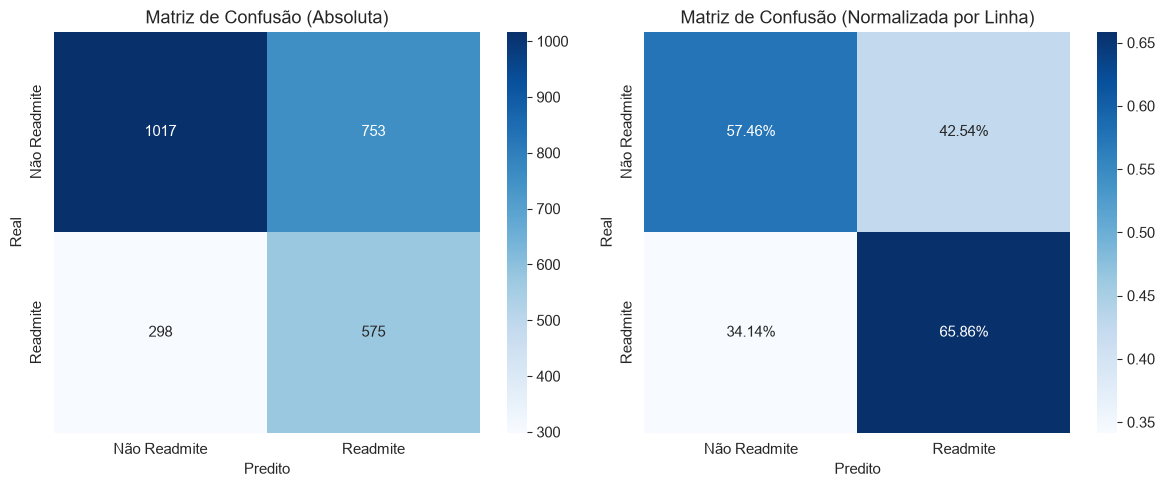

In [16]:
# Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print('=== MATRIZ DE CONFUSÃO ===')
print(f'                 Predito 0    Predito 1')
print(f'Real 0 (Não)      {tn:>6}         {fp:>6}')
print(f'Real 1 (Sim)      {fn:>6}         {tp:>6}')

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz absoluta
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Não Readmite', 'Readmite'],
            yticklabels=['Não Readmite', 'Readmite'])
axes[0].set_title('Matriz de Confusão (Absoluta)')
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Predito')

# Matriz normalizada
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[1],
            xticklabels=['Não Readmite', 'Readmite'],
            yticklabels=['Não Readmite', 'Readmite'])
axes[1].set_title('Matriz de Confusão (Normalizada por Linha)')
axes[1].set_ylabel('Real')
axes[1].set_xlabel('Predito')

plt.tight_layout()
plt.show()

In [17]:
# Classification Report completo
print('=== CLASSIFICATION REPORT ===')
report = classification_report(y_test, y_pred, target_names=['Não Readmite (0)', 'Readmite (1)'], digits=4)
print(report)

=== CLASSIFICATION REPORT ===
                  precision    recall  f1-score   support

Não Readmite (0)     0.7734    0.5746    0.6593      1770
    Readmite (1)     0.4330    0.6586    0.5225       873

        accuracy                         0.6023      2643
       macro avg     0.6032    0.6166    0.5909      2643
    weighted avg     0.6609    0.6023    0.6141      2643



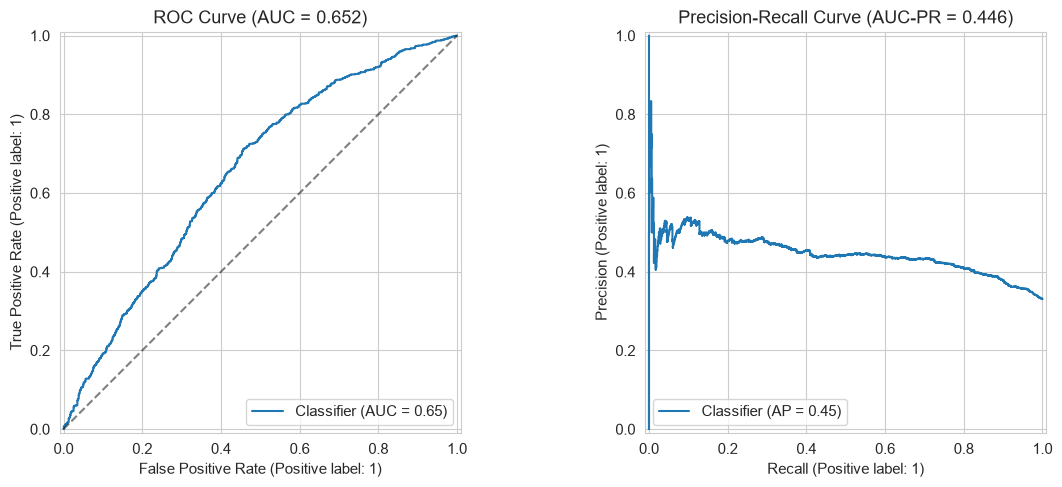

In [18]:
# Curvas ROC e Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0])
axes[0].set_title(f'ROC Curve (AUC = {auc_roc:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title(f'Precision-Recall Curve (AUC-PR = {auc_pr:.3f})')

plt.tight_layout()
plt.show()

## 8. Análise de Erros (FP e FN)

In [19]:
# Criar DataFrame de erros
errors_df = X_test.copy()
errors_df['y_true'] = y_test.values
errors_df['y_pred'] = y_pred
errors_df['y_proba'] = y_proba

# Falsos Positivos: predito 1, real 0
fp_mask = (errors_df['y_true'] == 0) & (errors_df['y_pred'] == 1)
fp_df = errors_df[fp_mask].copy()

# Falsos Negativos: predito 0, real 1
fn_mask = (errors_df['y_true'] == 1) & (errors_df['y_pred'] == 0)
fn_df = errors_df[fn_mask].copy()

print(f'Falsos Positivos (FP): {len(fp_df)}')
print(f'Falsos Negativos (FN): {len(fn_df)}')

# Probabilidade média nos erros
print(f'\nFP - Prob média classe 1: {fp_df["y_proba"].mean():.3f}')
print(f'FN - Prob média classe 1: {fn_df["y_proba"].mean():.3f}')

Falsos Positivos (FP): 753
Falsos Negativos (FN): 298

FP - Prob média classe 1: 0.933
FN - Prob média classe 1: 0.097


In [20]:
# Comparar features numéricas: FP vs FN vs Acertos
correct_mask = (errors_df['y_true'] == errors_df['y_pred'])
correct_df = errors_df[correct_mask].copy()

print('=== MÉDIAS DAS FEATURES NUMÉRICAS POR TIPO DE ERRO ===')
for feat in numeric_features:
    if feat in errors_df.columns:
        fp_mean = fp_df[feat].mean()
        fn_mean = fn_df[feat].mean()
        corr_mean = correct_df[feat].mean()
        print(f'{feat:40s} | FP: {fp_mean:8.2f} | FN: {fn_mean:8.2f} | Correto: {corr_mean:8.2f}')

=== MÉDIAS DAS FEATURES NUMÉRICAS POR TIPO DE ERRO ===
age                                      | FP:    60.43 | FN:    47.50 | Correto:    48.82
baseline_charlson_comorbidity_index      | FP:     2.95 | FN:     2.58 | Correto:     2.46
baseline_bmi                             | FP:    29.29 | FN:    28.26 | Correto:    28.67
length_of_stay_days                      | FP:     8.45 | FN:     3.74 | Correto:     4.82
revisit_count                            | FP:     2.49 | FN:     2.08 | Correto:     2.24
days_since_last_discharge_filled         | FP:    66.94 | FN:    63.58 | Correto:    66.58
systolic_bp                              | FP:   122.49 | FN:   121.26 | Correto:   122.04
diastolic_bp                             | FP:    80.88 | FN:    79.99 | Correto:    80.69
heart_rate                               | FP:    87.48 | FN:    75.87 | Correto:    78.32
respiratory_rate                         | FP:    18.94 | FN:    16.48 | Correto:    17.09
temperature                        

In [21]:
# Análise por department (categórica importante)
if 'department' in errors_df.columns:
    print('=== READMISSION RATE POR DEPARTMENT (TESTE) ===')
    dept_rates = errors_df.groupby('department').agg(
        n=('y_true', 'size'),
        readmit_rate=('y_true', 'mean'),
        fp_rate=('y_pred', lambda x: ((errors_df.loc[x.index, 'y_true']==0) & (x==1)).mean()),
        fn_rate=('y_pred', lambda x: ((errors_df.loc[x.index, 'y_true']==1) & (x==0)).mean()),
    ).sort_values('readmit_rate', ascending=False)
    print(dept_rates.round(4).to_string())

=== READMISSION RATE POR DEPARTMENT (TESTE) ===
                     n  readmit_rate  fp_rate  fn_rate
department                                            
Oncology           179        0.5084   0.4916   0.0056
ICU                257        0.4086   0.5681   0.0039
Orthopedics        294        0.3707   0.5680   0.0170
Cardiology         421        0.3563   0.5867   0.0048
General Surgery    250        0.3040   0.0240   0.2840
General Medicine  1004        0.2998   0.0986   0.1763
Pediatrics         184        0.1793   0.0000   0.1793
Obstetrics          54        0.1481   0.0000   0.1481


## 9. Interpretação dos Coeficientes (Naive Bayes)

GaussianNB não tem 'feature importance' direto, mas podemos ver as médias e variâncias por classe.

In [22]:
# Acessar parâmetros do GaussianNB
gnb = pipeline.named_steps['classifier']

# Theta_ = médias por classe e feature (após pré-processamento)
# Var_ = variâncias por classe e feature
print(f'Classes: {gnb.classes_}')
print(f'Class prior (log): {gnb.class_prior_}')
print(f'Theta shape (n_classes, n_features): {gnb.theta_.shape}')
print(f'Var shape: {gnb.var_.shape}')

Classes: [0 1]
Class prior (log): [0.66975688 0.33024312]
Theta shape (n_classes, n_features): (2, 83)
Var shape: (2, 83)


In [23]:
# Features mais discriminativas (maior diferença de médias entre classes, normalizada por variância)
feature_names = preprocessor_fitted.get_feature_names_out()

# Diferença de médias (classe 1 - classe 0)
mean_diff = gnb.theta_[1] - gnb.theta_[0]

# Variância pooled
pooled_var = (gnb.var_[0] + gnb.var_[1]) / 2

# Effect size (Cohen's d aproximado)
effect_size = mean_diff / np.sqrt(pooled_var + 1e-8)

# Top 15 features mais discriminativas
top_idx = np.argsort(np.abs(effect_size))[-15:][::-1]

print('=== TOP 15 FEATURES MAIS DISCRIMINATIVAS (Effect Size) ===')
for i in top_idx:
    print(f'{feature_names[i]:50s} | d={effect_size[i]:>7.3f} | μ₀={gnb.theta_[0,i]:>7.3f} | μ₁={gnb.theta_[1,i]:>7.3f}')

=== TOP 15 FEATURES MAIS DISCRIMINATIVAS (Effect Size) ===
baseline_charlson_comorbidity_index                | d=  0.438 | μ₀= -0.142 | μ₁=  0.289
is_elderly_0                                       | d= -0.435 | μ₀=  0.707 | μ₁=  0.499
is_elderly_1                                       | d=  0.435 | μ₀=  0.293 | μ₁=  0.501
age                                                | d=  0.410 | μ₀= -0.132 | μ₁=  0.267
disease_severity_Severe                            | d=  0.358 | μ₀=  0.208 | μ₁=  0.368
first_admission_flag_1                             | d= -0.336 | μ₀=  0.433 | μ₁=  0.274
first_admission_flag_0                             | d=  0.336 | μ₀=  0.567 | μ₁=  0.726
revisit_count                                      | d=  0.315 | μ₀= -0.104 | μ₁=  0.211
encounter_type_Emergency                           | d=  0.290 | μ₀=  0.183 | μ₁=  0.306
wbc_count                                          | d=  0.288 | μ₀= -0.096 | μ₁=  0.194
creatinine                                         

## 10. (Opcional) Comparação com Baseline: Regressão Logística

In [24]:
# Baseline: Logistic Regression (apenas referência)
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced'))
])

lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)
y_proba_lr = lr_pipeline.predict_proba(X_test)[:, 1]

print('=== COMPARAÇÃO: Naive Bayes vs Logistic Regression ===')
print(f'NB  - Acc: {accuracy_score(y_test, y_pred):.4f}, F1-macro: {f1_score(y_test, y_pred, average="macro"):.4f}, AUC: {roc_auc_score(y_test, y_proba):.4f}')
print(f'LR  - Acc: {accuracy_score(y_test, y_pred_lr):.4f}, F1-macro: {f1_score(y_test, y_pred_lr, average="macro"):.4f}, AUC: {roc_auc_score(y_test, y_proba_lr):.4f}')

print('\n--- NB Classification Report ---')
print(classification_report(y_test, y_pred, target_names=['Não Readmite', 'Readmite'], digits=4))

print('--- LR Classification Report ---')
print(classification_report(y_test, y_pred_lr, target_names=['Não Readmite', 'Readmite'], digits=4))

=== COMPARAÇÃO: Naive Bayes vs Logistic Regression ===
NB  - Acc: 0.6023, F1-macro: 0.5909, AUC: 0.6518
LR  - Acc: 0.6481, F1-macro: 0.6296, AUC: 0.7036

--- NB Classification Report ---
              precision    recall  f1-score   support

Não Readmite     0.7734    0.5746    0.6593      1770
    Readmite     0.4330    0.6586    0.5225       873

    accuracy                         0.6023      2643
   macro avg     0.6032    0.6166    0.5909      2643
weighted avg     0.6609    0.6023    0.6141      2643

--- LR Classification Report ---
              precision    recall  f1-score   support

Não Readmite     0.7869    0.6508    0.7124      1770
    Readmite     0.4758    0.6426    0.5468       873

    accuracy                         0.6481      2643
   macro avg     0.6314    0.6467    0.6296      2643
weighted avg     0.6841    0.6481    0.6577      2643



## 11. Exportação do Modelo (Pipeline Completo)

In [25]:
# Salvar pipeline completo
model_path = MODEL_DIR / 'modelo_nb.joblib'
joblib.dump(pipeline, model_path)

print(f'Modelo salvo em: {model_path.absolute()}')
print(f'Tamanho: {model_path.stat().st_size / 1e6:.2f} MB')

Modelo salvo em: W:\projetos\hospital-management\ml\notebooks\..\backend\model\modelo_nb.joblib
Tamanho: 0.01 MB


In [26]:
# Verificar se carrega corretamente
loaded_pipeline = joblib.load(model_path)

# Teste rápido
test_pred = loaded_pipeline.predict(X_test.iloc[:5])
test_proba = loaded_pipeline.predict_proba(X_test.iloc[:5])

print('Teste de carregamento OK')
print(f'Predições: {test_pred}')
print(f'Probabilidades shape: {test_proba.shape}')
print(f'São iguais ao original? {np.array_equal(test_pred, y_pred[:5])}')

Teste de carregamento OK
Predições: [0 1 1 0 1]
Probabilidades shape: (5, 2)
São iguais ao original? True


## 12. Criar Script de Teste Standalone (`ml/teste_carregamento.py`)

In [27]:
# Gerar script de teste
test_script = '''"""
Script standalone para testar carregamento e predição do modelo.
Uso: python teste_carregamento.py
"""
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

# Caminho do modelo
MODEL_PATH = Path(__file__).parent.parent / 'backend' / 'model' / 'modelo_nb.joblib'

# Exemplo de entrada (28 features na ordem do treino)
EXAMPLE_INPUT = {
    # Demografia
    'age': 72,
    'gender': 'M',
    'charlson_comorbidity_index': 3,
    'baseline_bmi': 28.5,
    'smoker_status': 'Former',
    'socioeconomic_tier': 'Middle',
    'residential_zone': 'Urban',
    'marital_status': 'Married',
    'is_elderly': 1,
    
    # Internação
    'encounter_type': 'Emergency',
    'admission_urgency': 'Emergency',
    'department': 'Cardiology',
    'length_of_stay_days': 5,
    'los_category': '4-7',
    'revisit_count': 2,
    'days_since_last_discharge_filled': 45,
    'first_admission_flag': 0,
    
    # Clínico na Alta
    'systolic_bp': 120,
    'diastolic_bp': 80,
    'heart_rate': 78,
    'respiratory_rate': 18,
    'temperature': 36.8,
    'spo2': 95,
    'glucose': 140,
    'creatinine': 1.3,
    'hemoglobin': 11.2,
    'wbc_count': 9.1,
    'disease_category': 'Cardiovascular',
    'disease_severity': 'Moderate',
    
    # Medicações
    'num_medications': 8,
    'num_therapeutic_classes': 5,
    'polypharmacy_flag': 1,
    'has_high_risk_med': 1,
    'has_anticoagulant': 1,
    'has_insulin': 0,
    'has_diuretic': 1,
    'has_beta_blocker': 1,
    'has_ace_arb': 1,
}

def main():
    print(f'Carregando modelo de: {MODEL_PATH}')
    
    if not MODEL_PATH.exists():
        print(f'ERRO: Modelo não encontrado em {MODEL_PATH}')
        return
    
    pipeline = joblib.load(MODEL_PATH)
    print('✓ Modelo carregado com sucesso')
    
    # Converter para DataFrame
    df = pd.DataFrame([EXAMPLE_INPUT])
    print(f'\nInput shape: {df.shape}')
    print(f'Colunas: {list(df.columns)}')
    
    # Predição
    pred = pipeline.predict(df)[0]
    proba = pipeline.predict_proba(df)[0]
    
    print(f'\n=== RESULTADO ===')
    print(f'Classe predita: {pred} ({"Alto Risco" if pred == 1 else "Baixo Risco"})')
    print(f'Probabilidade classe 0 (Não readmite): {proba[0]:.4f}')
    print(f'Probabilidade classe 1 (Readmite):     {proba[1]:.4f}')
    print(f'Score de risco (%): {proba[1]*100:.1f}%')
    
    # Verificar se predict_proba funciona
    assert hasattr(pipeline, 'predict_proba'), 'predict_proba não disponível'
    assert proba.shape == (2,), 'Probabilidades devem ter 2 classes'
    assert abs(proba.sum() - 1.0) < 1e-6, 'Probabilidades devem somar 1'
    
    print('\n✓ Todos os testes passaram!')

if __name__ == '__main__':
    main()
'''

test_path = Path('teste_carregamento.py')
test_path.write_text(test_script, encoding='utf-8')

print(f'Script de teste salvo em: {test_path.absolute()}')

Script de teste salvo em: W:\projetos\hospital-management\ml\notebooks\teste_carregamento.py


In [28]:
# Testar o script standalone
import subprocess
import sys

result = subprocess.run([sys.executable, 'teste_carregamento.py'], capture_output=True, text=True, cwd=Path.cwd())
print(result.stdout)
if result.stderr:
    print('STDERR:', result.stderr)


STDERR:   File "W:\projetos\hospital-management\ml\notebooks\teste_carregamento.py", line 74
    print(f'
          ^
SyntaxError: unterminated f-string literal (detected at line 74)



## 13. Atualizar `ml/CONTRATO.md` com Features Finais

In [29]:
# Gerar CONTRATO.md
contrato_content = '''# Contrato de API — Predição Readmissão 30 Dias

> **Versão do modelo**: 1.0  
> **Algoritmo**: Naive Bayes (GaussianNB) com ColumnTransformer  
> **Features**: 28 (9 numéricas contínuas + 19 categóricas/OneHot)  
> **Target**: `readmission_30d` (0 = Não readmite, 1 = Readmite em ≤30 dias)

---

## Entrada (POST /api/v1/predict/readmission-30d)

Campos **obrigatórios**, na **ordem exata** usada no treino:

### 1. Demografia (9 campos)

| Campo | Tipo | Valores Aceitos | Descrição |
|-------|------|-----------------|-----------|
| `age` | integer | 0–110 | Idade do paciente |
| `gender` | string | `"M"`, `"F"` | Sexo biológico |
| `charlson_comorbidity_index` | integer | 0–15 | Índice de Charlson (comorbidades basais) |
| `baseline_bmi` | float | 10.0–60.0 | IMC basal (kg/m²) |
| `smoker_status` | string | `"Never"`, `"Former"`, `"Current"` | Status tabágico |
| `socioeconomic_tier` | string | `"Low"`, `"Middle"`, `"High"` | Nível socioeconômico |
| `residential_zone` | string | `"Rural"`, `"Suburban"`, `"Urban"` | Zona residencial |
| `marital_status` | string | `"Single"`, `"Married"`, `"Divorced"`, `"Widowed"` | Estado civil |
| `is_elderly` | integer | `0`, `1` | Flag derivado: `age >= 65` |

### 2. Internação (8 campos)

| Campo | Tipo | Valores Aceitos | Descrição |
|-------|------|-----------------|-----------|
| `encounter_type` | string | `"Emergency"`, `"Inpatient"`, `"Outpatient"` | Tipo de atendimento |
| `admission_urgency` | string | `"Elective"`, `"Urgent"`, `"Emergency"` | Urgência da admissão |
| `department` | string | `"General Medicine"`, `"Cardiology"`, `"ICU"`, `"Orthopedics"`, `"General Surgery"`, `"Pediatrics"`, `"Oncology"`, `"Obstetrics"` | Departamento |
| `length_of_stay_days` | integer | 0–60 | Dias de internação |
| `los_category` | string | `"0-1"`, `"2-3"`, `"4-7"`, `"8+"` | Bin de LOS (derivado) |
| `revisit_count` | integer | 0–20 | Número de revisitas anteriores |
| `days_since_last_discharge_filled` | integer | -1 a 3650 | Dias desde última alta (-1 = primeira internação) |
| `first_admission_flag` | integer | `0`, `1` | Flag: 1 se primeira internação |

### 3. Clínico na Alta (12 campos)

| Campo | Tipo | Valores Aceitos | Unidade |
|-------|------|-----------------|---------|
| `systolic_bp` | integer | 60–250 | mmHg |
| `diastolic_bp` | integer | 30–150 | mmHg |
| `heart_rate` | integer | 30–200 | bpm |
| `respiratory_rate` | integer | 5–60 | resp/min |
| `temperature` | float | 34.0–42.0 | °C |
| `spo2` | integer | 70–100 | % |
| `glucose` | integer | 40–500 | mg/dL |
| `creatinine` | float | 0.3–15.0 | mg/dL |
| `hemoglobin` | float | 4.0–20.0 | g/dL |
| `wbc_count` | float | 1.0–50.0 | ×10³/µL |
| `disease_category` | string | `"Respiratory"`, `"Cardiovascular"`, `"Infectious"`, `"Renal"`, `"GI"`, `"Endocrine"`, `"Oncology"`, `"Musculoskeletal"`, `"Trauma"`, `"Pediatrics"`, `"Obstetrics"` | Categoria da doença |
| `disease_severity` | string | `"Mild"`, `"Moderate"`, `"Severe"`, `"Critical"` | Gravidade da doença |

### 4. Medicações na Alta (9 campos)

| Campo | Tipo | Valores Aceitos | Descrição |
|-------|------|-----------------|-----------|
| `num_medications` | integer | 0–30 | Número de medicações distintas (NDC) |
| `num_therapeutic_classes` | integer | 0–15 | Número de classes terapêuticas distintas |
| `polypharmacy_flag` | integer | `0`, `1` | `num_medications >= 5` |
| `has_high_risk_med` | integer | `0`, `1` | Alguma medicação de alto risco (flag original) |
| `has_anticoagulant` | integer | `0`, `1` | Warfarina, apixabana, rivaroxabana, heparina, etc. |
| `has_insulin` | integer | `0`, `1` | Qualquer insulina |
| `has_diuretic` | integer | `0`, `1` | Furosemida, hidroclorotiazida, espironolactona, etc. |
| `has_beta_blocker` | integer | `0`, `1` | Metoprolol, carvedilol, atenolol, etc. |
| `has_ace_arb` | integer | `0`, `1` | Lisinopril, losartana, ramipril, valsartana, etc. |

---

## Saída (JSON Response)

```json
{
  "predicted_class": 0,
  "class_label": "Baixo Risco",
  "probabilities": {
    "0": 0.74,
    "1": 0.26
  },
  "risk_score_percent": 26,
  "recommendation": "BAIXO RISCO: Alta padrão com orientações de rotina",
  "model_version": "1.0"
}
```

| Campo | Tipo | Descrição |
|-------|------|-----------|
| `predicted_class` | integer | `0` (Baixo Risco) ou `1` (Alto Risco) |
| `class_label` | string | Rótulo legível para exibição |
| `probabilities` | object | Probabilidade por classe (soma = 1.0) |
| `risk_score_percent` | integer | `probabilities["1"] * 100` arredondado |
| `recommendation` | string | Recomendação clínica acionável |
| `model_version` | string | Versão do modelo deployado |

---

## Exemplo de Requisição (cURL)

```bash
curl -X POST http://localhost:5000/api/v1/predict/readmission-30d \
  -H "Content-Type: application/json" \
  -d '{
    "age": 72,
    "gender": "M",
    "charlson_comorbidity_index": 3,
    "baseline_bmi": 28.5,
    "smoker_status": "Former",
    "socioeconomic_tier": "Middle",
    "residential_zone": "Urban",
    "marital_status": "Married",
    "is_elderly": 1,
    "encounter_type": "Emergency",
    "admission_urgency": "Emergency",
    "department": "Cardiology",
    "length_of_stay_days": 5,
    "los_category": "4-7",
    "revisit_count": 2,
    "days_since_last_discharge_filled": 45,
    "first_admission_flag": 0,
    "systolic_bp": 120,
    "diastolic_bp": 80,
    "heart_rate": 78,
    "respiratory_rate": 18,
    "temperature": 36.8,
    "spo2": 95,
    "glucose": 140,
    "creatinine": 1.3,
    "hemoglobin": 11.2,
    "wbc_count": 9.1,
    "disease_category": "Cardiovascular",
    "disease_severity": "Moderate",
    "num_medications": 8,
    "num_therapeutic_classes": 5,
    "polypharmacy_flag": 1,
    "has_high_risk_med": 1,
    "has_anticoagulant": 1,
    "has_insulin": 0,
    "has_diuretic": 1,
    "has_beta_blocker": 1,
    "has_ace_arb": 1
  }'
```

---

## Notas para Backend

1. **Ordem das colunas**: O `ColumnTransformer` espera as features na ordem exata listada acima.
2. **Valores categóricos**: Devem corresponder exatamente (case-sensitive) aos valores vistos no treino.
3. **`days_since_last_discharge_filled`**: Use `-1` para primeira internação (o modelo aprendeu isso).
4. **`los_category`**: É derivado de `length_of_stay_days`; o backend pode calcular ou receber pré-calculado.
5. **`is_elderly`**: Derivado de `age >= 65`; o backend deve calcular.
6. **Missing values**: O pipeline trata NaN nas numéricas (imputação via treino) e `handle_unknown='ignore'` nas categóricas.
7. **`predict_proba`**: Disponível e funcional — retorna array shape (n_samples, 2).
8. **Versão sklearn**: Treinado com scikit-learn 1.5.x; backend deve usar versão compatível.
'''

contrato_path = Path('../CONTRATO.md')
contrato_path.write_text(contrato_content, encoding='utf-8')

print(f'CONTRATO.md atualizado em: {contrato_path.absolute()}')

CONTRATO.md atualizado em: W:\projetos\hospital-management\ml\notebooks\..\CONTRATO.md


## 14. Resumo Final e Métricas para README

In [30]:
# Resumo final para documentação
print('=' * 60)
print('RESUMO FINAL DO MODELO')
print('=' * 60)
print(f'Dataset: Hospital Management Data (Kaggle)')
print(f'Target: readmission_30d (binária, 67/33%')
print(f'Features: {len(existing)} (ordem fixa no CONTRATO.md)')
print(f'Split: 80/20 estratificado, random_state=42')
print(f'Pipeline: ColumnTransformer(StandardScaler+OneHot) → GaussianNB')
print(f'')
print(f'MÉTRICAS NO TESTE (20% = {X_test.shape[0]:,} amostras):')
print(f'  Accuracy:           {accuracy:.4f}')
print(f'  Precision (macro):  {precision_macro:.4f}')
print(f'  Recall (macro):     {recall_macro:.4f}')
print(f'  F1-score (macro):   {f1_macro:.4f}')
print(f'  AUC-ROC:            {auc_roc:.4f}')
print(f'  AUC-PR:             {auc_pr:.4f}')
print(f'')
print(f'Matriz de Confusão:')
print(f'  TN={tn}, FP={fp}')
print(f'  FN={fn}, TP={tp}')
print(f'')
print(f'Modelo salvo: {model_path.absolute()}')
print(f'Script teste: teste_carregamento.py')
print(f'Contrato: ../CONTRATO.md')
print('=' * 60)

RESUMO FINAL DO MODELO
Dataset: Hospital Management Data (Kaggle)
Target: readmission_30d (binária, 67/33%
Features: 38 (ordem fixa no CONTRATO.md)
Split: 80/20 estratificado, random_state=42
Pipeline: ColumnTransformer(StandardScaler+OneHot) → GaussianNB

MÉTRICAS NO TESTE (20% = 2,643 amostras):
  Accuracy:           0.6023
  Precision (macro):  0.6032
  Recall (macro):     0.6166
  F1-score (macro):   0.5909
  AUC-ROC:            0.6518
  AUC-PR:             0.4455

Matriz de Confusão:
  TN=1017, FP=753
  FN=298, TP=575

Modelo salvo: W:\projetos\hospital-management\ml\notebooks\..\backend\model\modelo_nb.joblib
Script teste: teste_carregamento.py
Contrato: ../CONTRATO.md


## 15. Limitações (para README e Apresentação)

1. **Dataset sintético** — Padrões podem não generalizar para EHR reais
2. **Features de alta** — Vitals/labs/meds coletados **no momento da alta**; em produção usar valores *pré-alta* (24h antes) ou prever *antes* da decisão de alta
3. **`days_since_last_discharge` = 38% NaN** → Flag `first_admission_flag` captura; imputação com -1
4. **Independência NB** — Features correlacionadas (PA, meds cardíacas, labs) violam假设
5. **Desbalanceamento 67/33** → Macro-F1 usado; considerar *threshold tuning* se custo FN >> FP
6. **Split aleatório** — Em produção usar *time-series split* (treino: meses antigos, teste: mês recente)
7. **Generalização** — Dataset sem localização; práticas de alta variam por país/sistema
8. **Baseline LR superior** — Regressão Logística costuma bater NB em features correlacionadas; NB escolhido por requisito do trabalho